In [8]:
import pandas as pd
import numpy as np   # importing important libraries
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,                 # importing features from sklearn library
    precision_score,
    recall_score,
    f1_score,
    classification_report
)


In [ ]:
#read the dataset

df = pd.read_csv('../data/mobile_price.csv') # reading dataset from the csv file
print(df.shape)

(2000, 21)


In [ ]:

# 2. Separate features (X) and target (y)
# X contains phone specifications.
# y contains the price category that we want to predict. 
X = df.drop("price_range", axis=1)
y = df["price_range"]

print("\nFeatures shape:", X.shape) 
print("Target shape:", y.shape)


Features shape: (2000, 20)
Target shape: (2000,)


In [ ]:
# 3. Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
) # to ensure that the training and testing sets have a similar distribution of price categories, we use stratified sampling.


print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)


Training data shape: (1600, 20)
Testing data shape: (400, 20)


In [12]:
# 4. Fill missing values using the median of training data
# The same training medians are used for the test data.
X_train = X_train.fillna(X_train.median())
X_test = X_test.fillna(X_train.median())

print("\nMissing values in training data:", X_train.isnull().sum().sum())
print("Missing values in testing data:", X_test.isnull().sum().sum())


Missing values in training data: 0
Missing values in testing data: 0


In [ ]:

# 5. Feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)# using fit_transform on the training data to compute the mean and standard deviation, and then scale the training data accordingly.
X_test_scaled = scaler.transform(X_test)

print("\nFeature scaling completed.")


Feature scaling completed.


In [ ]:
# 6. Create and train the Logistic Regression model
model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train) # fitting the model to the scaled training data and corresponding target values.

print("\nLogistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [ ]:
# 7. Make predictions on the test data
y_pred = model.predict(X_test_scaled)

print("\nFirst 20 predicted classes:")#predicting the price categories for the first 20 samples in the test set and printing them.
print(y_pred[:20])

print("\nFirst 20 actual classes:")
print(y_test.iloc[:20].values)



First 20 predicted classes:
[3 1 0 2 3 2 0 0 1 0 3 0 0 1 3 3 2 0 1 3]

First 20 actual classes:
[3 1 0 2 3 2 0 0 1 0 3 0 0 1 3 3 2 0 1 3]


In [ ]:
# 8. Evaluate model performance
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)
# calculating accuracy, precision, recall, and F1-score using the true labels and predicted labels.

print("\n---------- MODEL EVALUATION ----------")
print("Accuracy:", accuracy)
print("Accuracy percentage:", accuracy * 100, "%")
print("Weighted Precision:", precision)
print("Weighted Recall:", recall)
print("Weighted F1-score:", f1)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=["Low Cost", "Medium Cost", "High Cost", "Very High Cost"],
    zero_division=0
))



---------- MODEL EVALUATION ----------
Accuracy: 0.965
Accuracy percentage: 96.5 %
Weighted Precision: 0.9650445632798573
Weighted Recall: 0.965
Weighted F1-score: 0.9649863177272501

Classification Report:
                precision    recall  f1-score   support

      Low Cost       0.99      0.98      0.98       100
   Medium Cost       0.96      0.96      0.96       100
     High Cost       0.95      0.94      0.94       100
Very High Cost       0.96      0.98      0.97       100

      accuracy                           0.96       400
     macro avg       0.97      0.96      0.96       400
  weighted avg       0.97      0.96      0.96       400




Confusion Matrix:
[[98  2  0  0]
 [ 1 96  3  0]
 [ 0  2 94  4]
 [ 0  0  2 98]]


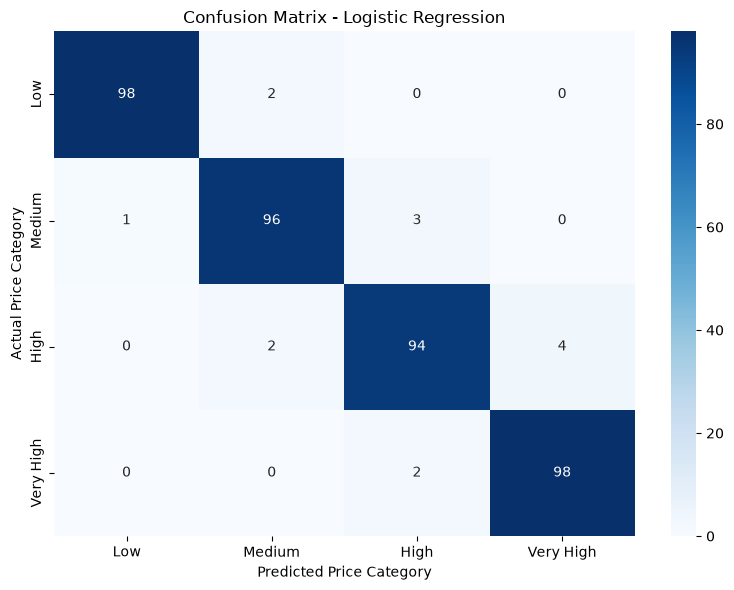

In [ ]:

# 9. Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2, 3])

print("\nConfusion Matrix:")
print(cm)
#confusion matrix is a table that is used to evaluate the performance of a classification model. It compares the predicted labels with the true labels and shows how many instances were correctly or incorrectly classified for each class.
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low", "Medium", "High", "Very High"],
    yticklabels=["Low", "Medium", "High", "Very High"]
)
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Price Category")
plt.ylabel("Actual Price Category")
plt.tight_layout()
plt.show()


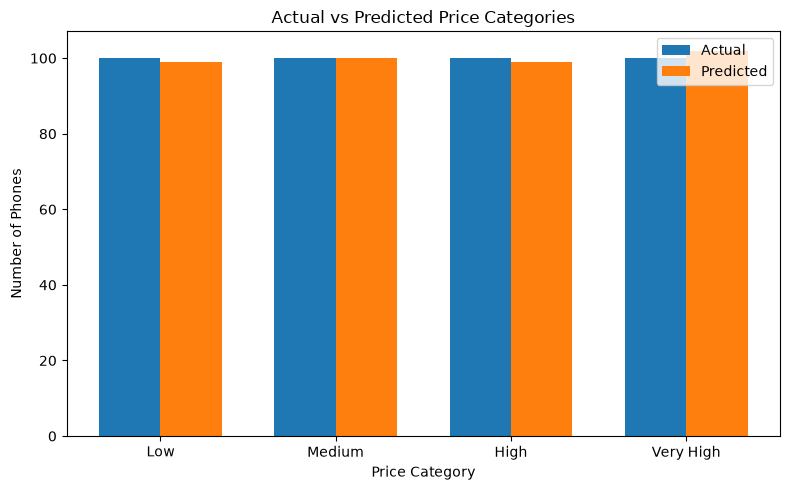

In [ ]:
# 10. Compare actual and predicted class counts
actual_counts = y_test.value_counts().sort_index()
predicted_counts = pd.Series(y_pred).value_counts().sort_index()

class_names = ["Low", "Medium", "High", "Very High"]
x = np.arange(4)     #comparing the number of phones in each price category for both actual and predicted values using a bar chart.
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - width / 2, actual_counts.reindex([0, 1, 2, 3], fill_value=0),
        width, label="Actual")
plt.bar(x + width / 2, predicted_counts.reindex([0, 1, 2, 3], fill_value=0),
        width, label="Predicted")

plt.title("Actual vs Predicted Price Categories")
plt.xlabel("Price Category")
plt.ylabel("Number of Phones")
plt.xticks(x, class_names)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# 11. Predict the category of one phone from the test set
sample = X_test_scaled[0].reshape(1, -1)
sample_prediction = model.predict(sample)  #predicting the price category for a single phone sample from the test set.

category_names = {
    0: "Low Cost",
    1: "Medium Cost",
    2: "High Cost",
    3: "Very High Cost"
}
# 12. Display the prediction result for the sample phone
print("\n---------- ONE PHONE PREDICTION ----------")
print("Predicted class:", sample_prediction[0])
print("Predicted category:", category_names[sample_prediction[0]])
print("Actual class:", y_test.iloc[0])
print("Actual category:", category_names[y_test.iloc[0]])


---------- ONE PHONE PREDICTION ----------
Predicted class: 3
Predicted category: Very High Cost
Actual class: 3
Actual category: Very High Cost
